In [1]:
%pip install -q -U langgraph

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 256.0/256.0 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.4/162.4 kB 7.3 MB/s eta 0:00:00


In [2]:
from typing import TypedDict, List
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt, Command

print("LangGraph memory setup successful.")

LangGraph memory setup successful.


In [3]:
class AgentState(TypedDict, total=False):
    user_input: str
    classification: str
    needs_human_review: bool
    route_decision: str
    human_feedback: str
    response: str
    messages: List[str]


def classify_node(state: AgentState):
    text = state["user_input"].lower()
    needs_review = any(
        word in text
        for word in ["medical", "legal", "financial", "high risk"]
    )

    return {
        "classification": "needs_review" if needs_review else "general",
        "needs_human_review": needs_review,
        "messages": state.get("messages", []) + [
            f"User: {state['user_input']}"
        ]
    }


print("Conversation state and classification node created.")

Conversation state and classification node created.


In [4]:
def route_node(state: AgentState):
    return {"route_decision": "human_review"}


def respond_node(state: AgentState):
    if state["needs_human_review"]:
        feedback = interrupt({
            "message": "Human review required.",
            "user_input": state["user_input"],
            "question": "Enter guidance to continue."
        })

        response = f"Response based on human guidance: {feedback}"
        messages = state.get("messages", []) + [
            f"Human: {feedback}",
            f"Assistant: {response}"
        ]
    else:
        response = f"General response to: {state['user_input']}"
        messages = state.get("messages", []) + [
            f"Assistant: {response}"
        ]

    return {
        "human_feedback": (
            str(feedback) if state["needs_human_review"] else ""
        ),
        "response": response,
        "messages": messages
    }


print("Route and response nodes created.")

Route and response nodes created.


In [5]:
def choose_route(state: AgentState):
    return (
        "route"
        if state["classification"] == "needs_review"
        else "respond"
    )


builder = StateGraph(AgentState)
builder.add_node("classify", classify_node)
builder.add_node("route", route_node)
builder.add_node("respond", respond_node)

builder.add_edge(START, "classify")
builder.add_conditional_edges(
    "classify",
    choose_route,
    {"route": "route", "respond": "respond"}
)
builder.add_edge("route", "respond")
builder.add_edge("respond", END)

memory = MemorySaver()
graph = builder.compile(checkpointer=memory)

print("Three-node graph compiled with conversation checkpointing.")

Three-node graph compiled with conversation checkpointing.


In [6]:
test_inputs = [
    "Explain machine learning.",
    "What is Python?",
    "Give me study tips.",
    "Explain neural networks.",
    "How can I improve my coding?"
]

for i, text in enumerate(test_inputs, start=1):
    result = graph.invoke(
        {"user_input": text, "messages": []},
        config={"configurable": {"thread_id": f"w10d3-test-{i}"}}
    )
    print(f"{i}. {text}")
    print("   Classification:", result["classification"])
    print("   Response:", result["response"])

1. Explain machine learning.
   Classification: general
   Response: General response to: Explain machine learning.
2. What is Python?
   Classification: general
   Response: General response to: What is Python?
3. Give me study tips.
   Classification: general
   Response: General response to: Give me study tips.
4. Explain neural networks.
   Classification: general
   Response: General response to: Explain neural networks.
5. How can I improve my coding?
   Classification: general
   Response: General response to: How can I improve my coding?


In [7]:
conversation_config = {
    "configurable": {"thread_id": "bhavana-conversation-1"}
}

turn1 = graph.invoke(
    {"user_input": "My favourite subject is machine learning."},
    config=conversation_config
)

turn2 = graph.invoke(
    {"user_input": "What is my favourite subject?"},
    config=conversation_config
)

print("Turn 1 response:", turn1["response"])
print("Turn 2 response:", turn2["response"])
print("Messages retained:", turn2.get("messages", []))

Turn 1 response: General response to: My favourite subject is machine learning.
Turn 2 response: General response to: What is my favourite subject?
Messages retained: ['User: My favourite subject is machine learning.', 'Assistant: General response to: My favourite subject is machine learning.', 'User: What is my favourite subject?', 'Assistant: General response to: What is my favourite subject?']


In [8]:
review_config = {
    "configurable": {"thread_id": "w10d3-human-review"}
}

paused = graph.invoke(
    {"user_input": "I need guidance about a legal decision."},
    config=review_config
)

print("Graph paused for review:")
print(paused["__interrupt__"])

Graph paused for review:
[Interrupt(value={'message': 'Human review required.', 'user_input': 'I need guidance about a legal decision.', 'question': 'Enter guidance to continue.'}, id='db682ff8c2605ef98e85d4b8df0e7d76', response_schema=None)]


In [9]:
feedback = input("Enter human approval or guidance: ")

resumed = graph.invoke(
    Command(resume=feedback),
    config=review_config
)

print("Graph resumed successfully.")
print("Human feedback:", resumed["human_feedback"])
print("Final response:", resumed["response"])

Enter human approval or guidance: Approved. Provide general information and recommend consulting a qualified professional.
Graph resumed successfully.
Human feedback: Approved. Provide general information and recommend consulting a qualified professional.
Final response: Response based on human guidance: Approved. Provide general information and recommend consulting a qualified professional.


In [10]:
general = graph.invoke(
    {"user_input": "Explain artificial intelligence."},
    config={"configurable": {"thread_id": "verify-general"}}
)

review = graph.invoke(
    {"user_input": "I need help with a legal decision."},
    config={"configurable": {"thread_id": "verify-review"}}
)

assert general["classification"] == "general"
assert review["classification"] == "needs_review"
assert review["route_decision"] == "human_review"

print("General routing: PASS")
print("Human-review routing: PASS")
print("Conditional routing verified.")

General routing: PASS
Human-review routing: PASS
Conditional routing verified.


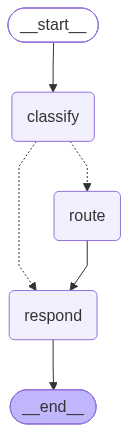

In [11]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

In [12]:
from pathlib import Path

report = """# W10D3: LangGraph + Memory — Persistent Conversations

- Built a three-node LangGraph: classify, route, respond.
- Tested five general inputs.
- Added conditional routing based on classification.
- Used MemorySaver checkpointing with thread IDs.
- Tested a human-in-the-loop interrupt and resume.
"""

Path("W10D3_LangGraph_Persistent_Conversations.md").write_text(
    report, encoding="utf-8"
)

print("W10D3 report saved.")

W10D3 report saved.
